Các thư viện bổ sung sau đây là cần thiết để chạy notebook này. Lưu ý rằng việc chạy trên Colab vẫn đang trong quá trình thử nghiệm, vui lòng báo cáo sự cố trên Github nếu bạn gặp bất kỳ vấn đề nào.

In [ ]:
!pip install d2l==1.0.3 --no-deps


# Dropout
:label:`sec_dropout`

Hãy cùng suy nghĩ một chút về những gì chúng ta mong đợi từ một mô hình dự báo tốt. Chúng ta muốn nó hoạt động tốt trên dữ liệu chưa từng thấy (unseen data).
Lý thuyết tổng quát hóa cổ điển gợi ý rằng để thu hẹp khoảng cách giữa hiệu suất huấn luyện (train) và kiểm thử (test), chúng ta nên hướng tới một mô hình đơn giản.
Sự đơn giản có thể thể hiện dưới dạng số lượng chiều (parameters) nhỏ.
Chúng ta đã khám phá điều này khi thảo luận về các hàm cơ sở đơn thức của mô hình tuyến tính trong :numref:`sec_generalization_basics`.
Ngoài ra, như chúng ta đã thấy khi thảo luận về suy giảm trọng số (weight decay - chuẩn hóa $\ell_2$) trong :numref:`sec_weight_decay`, chuẩn nghịch đảo của các tham số cũng đại diện cho một thước đo hữu ích về sự đơn giản.
Một khái niệm hữu ích khác về sự đơn giản là độ mượt (smoothness), tức là hàm số không nên quá nhạy cảm với những thay đổi nhỏ trong đầu vào của nó.
Ví dụ, khi chúng ta phân loại hình ảnh, chúng ta kỳ vọng rằng việc thêm một số nhiễu ngẫu nhiên vào các điểm ảnh (pixels) hầu như sẽ không gây hại.

:citet:`Bishop.1995` đã chính thức hóa ý tưởng này khi ông chứng minh rằng việc huấn luyện với nhiễu đầu vào tương đương với chuẩn hóa Tikhonov.
Công trình này đã rút ra một mối liên hệ toán học rõ ràng giữa yêu cầu một hàm số phải mượt mà (và do đó đơn giản), và yêu cầu nó phải có khả năng chống chịu trước các biến động ở đầu vào.

Sau đó, :citet:`Srivastava.Hinton.Krizhevsky.ea.2014` đã phát triển một ý tưởng thông minh để áp dụng ý tưởng của Bishop vào các lớp ẩn bên trong của mạng nơ-ron.
Ý tưởng của họ, được gọi là *dropout* (bỏ học), liên quan đến việc truyền nhiễu trong khi tính toán từng lớp bên trong trong quá trình lan truyền xuôi (forward propagation), và nó đã trở thành một kỹ thuật tiêu chuẩn để huấn luyện các mạng nơ-ron sâu.
Phương pháp này được gọi là *dropout* vì chúng ta thực sự loại bỏ (drop out) một số nơ-ron trong quá trình huấn luyện.
Trong suốt quá trình huấn luyện, ở mỗi lượt lặp, dropout tiêu chuẩn bao gồm việc đặt giá trị của một tỷ lệ nút nhất định trong mỗi lớp về 0 trước khi tính toán lớp tiếp theo.

Để làm rõ, chúng ta đang liên kết câu chuyện này với công trình của Bishop.
Bài báo gốc về dropout đưa ra trực giác thông qua một phép so sánh thú vị với sự sinh sản hữu tính.
Các tác giả lập luận rằng sự quá khớp (overfitting) của mạng nơ-ron được đặc trưng bởi một trạng thái mà trong đó mỗi lớp phụ thuộc vào một tổ hợp kích hoạt cụ thể trong lớp trước đó, gọi tình trạng này là *sự đồng thích nghi* (co-adaptation).
Họ cho rằng Dropout phá vỡ sự đồng thích nghi này giống như cách sinh sản hữu tính được cho là phá vỡ các gen đồng thích nghi.
Mặc dù lời giải thích lý thuyết này chắc chắn còn gây tranh cãi, nhưng bản thân kỹ thuật dropout đã chứng tỏ được hiệu quả lâu dài, và các biến thể của dropout được triển khai trong hầu hết các thư viện học sâu hiện nay.

Thách thức chính là làm thế nào để truyền nhiễu này vào.
Một ý tưởng là truyền nhiễu theo cách *không chệch* (unbiased) để giá trị kỳ vọng của mỗi lớp—khi cố định các lớp khác—bằng với giá trị của nó khi không có nhiễu.
Trong nghiên cứu của Bishop, ông đã thêm nhiễu Gaussian vào các đầu vào của một mô hình tuyến tính.
Tại mỗi lượt lặp huấn luyện, ông thêm nhiễu được lấy mẫu từ một phân phối có trung bình bằng 0 $\epsilon \sim \mathcal{N}(0,\sigma^2)$ vào đầu vào $\mathbf{x}$, tạo ra một điểm bị biến đổi $\mathbf{x}' = \mathbf{x} + \epsilon$.
Theo kỳ vọng, $E[\mathbf{x}'] = \mathbf{x}$.

Trong chuẩn hóa dropout tiêu chuẩn, người ta đặt một tỷ lệ nút nhất định trong mỗi lớp về 0 và sau đó *khử chệch* (debias) mỗi lớp bằng cách chia cho tỷ lệ các nút được giữ lại (không bị bỏ).
Nói cách khác, với *xác suất dropout* $p$, mỗi giá trị kích hoạt trung gian $h$ được thay thế bằng một biến ngẫu nhiên $h'$ như sau:

$$
\begin{aligned}
h' =
\begin{cases}
    0 & \textrm{ với xác suất } p \\
    \frac{h}{1-p} & \textrm{ ngược lại}
\end{cases}
\end{aligned}
$$

Theo thiết kế, giá trị kỳ vọng vẫn không thay đổi, nghĩa là $E[h'] = h$.

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l

## Dropout trong Thực tế

Hãy nhớ lại mô hình MLP với một lớp ẩn và năm đơn vị ẩn từ :numref:`fig_mlp`.
Khi chúng ta áp dụng dropout vào một lớp ẩn, đặt mỗi đơn vị ẩn về 0 với xác suất $p$, kết quả có thể được xem như một mạng chỉ chứa một tập hợp con của các nơ-ron ban đầu.
Trong :numref:`fig_dropout2`, $h_2$ và $h_5$ đã bị loại bỏ.
Do đó, việc tính toán đầu ra không còn phụ thuộc vào $h_2$ hoặc $h_5$ và các gradient tương ứng của chúng cũng biến mất khi thực hiện lan truyền ngược (backpropagation).
Bằng cách này, việc tính toán lớp đầu ra không thể bị phụ thuộc quá mức vào bất kỳ một phần tử nào của $h_1, \ldots, h_5$.

![Mạng MLP trước và sau khi áp dụng dropout.](http://d2l.ai/_images/dropout2.svg)
:label:`fig_dropout2`

Thông thường, chúng ta tắt dropout tại thời điểm kiểm thử (test time).
Khi có một mô hình đã huấn luyện và một mẫu dữ liệu mới, chúng ta không loại bỏ bất kỳ nút nào và do đó không cần phải chuẩn hóa.
Tuy nhiên, có một số ngoại lệ: một số nhà nghiên cứu sử dụng dropout tại thời điểm kiểm thử như một phương pháp phỏng đoán để ước lượng *độ không chắc chắn* (uncertainty) của các dự báo từ mạng nơ-ron: nếu các dự báo đồng nhất trên nhiều đầu ra dropout khác nhau, thì chúng ta có thể nói rằng mạng tự tin hơn.

## Triển khai từ đầu (Scratch)

Để triển khai hàm dropout cho một lớp duy nhất, chúng ta phải rút ra các mẫu từ một biến ngẫu nhiên Bernoulli (nhị phân) có số chiều bằng số chiều của lớp,
trong đó biến ngẫu nhiên nhận giá trị $1$ (giữ lại) với xác suất $1-p$ và $0$ (loại bỏ) với xác suất $p$.
Một cách dễ dàng để triển khai việc này là trước tiên rút các mẫu từ phân phối đều $U[0, 1]$.
Sau đó, chúng ta giữ lại những nút có mẫu tương ứng lớn hơn $p$, và loại bỏ những nút còn lại.

Trong đoạn mã dưới đây, chúng ta (**triển khai hàm `dropout_layer` để loại bỏ các phần tử trong tensor đầu vào `X` với xác suất `dropout`**), sau đó điều chỉnh lại tỷ lệ các phần tử còn lại như mô tả ở trên: chia các phần tử sống sót cho `1.0 - dropout`.

In [ ]:
def dropout_layer(X, dropout):
    # Đảm bảo giá trị dropout nằm trong khoảng từ 0 đến 1
    assert 0 <= dropout <= 1
    # Nếu tỷ lệ dropout là 1, trả về tensor toàn số 0 có cùng kích thước với X
    if dropout == 1: return torch.zeros_like(X)
    # Tạo một mặt nạ (mask) nhị phân: giữ lại (1) nếu giá trị ngẫu nhiên > dropout, ngược lại bỏ (0)
    mask = (torch.rand(X.shape) > dropout).float()
    # Nhân đầu vào X với mặt nạ và chia cho (1 - dropout) để giữ nguyên giá trị kỳ vọng
    return mask * X / (1.0 - dropout)

Chúng ta có thể [**thử nghiệm hàm `dropout_layer` trên một vài ví dụ**].
Trong các dòng mã tiếp theo, chúng ta truyền đầu vào `X` qua phép toán dropout với các xác suất lần lượt là 0, 0.5, và 1.

In [ ]:
# Tạo một tensor X chạy từ 0 đến 15 có kích thước (2, 8)
X = torch.arange(16, dtype = torch.float32).reshape((2, 8))
# Thử nghiệm với các mức dropout khác nhau
print('dropout_p = 0:', dropout_layer(X, 0))
print('dropout_p = 0.5:', dropout_layer(X, 0.5))
print('dropout_p = 1:', dropout_layer(X, 1))

dropout_p = 0: tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
dropout_p = 0.5: tensor([[ 0.,  2.,  0.,  6.,  8.,  0.,  0.,  0.],
        [16., 18., 20., 22., 24., 26., 28., 30.]])
dropout_p = 1: tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


### Định nghĩa Mô hình

Mô hình dưới đây áp dụng dropout vào đầu ra của mỗi lớp ẩn (sau hàm kích hoạt).
Chúng ta có thể thiết lập xác suất dropout riêng biệt cho từng lớp.
Một lựa chọn phổ biến là đặt xác suất dropout thấp hơn ở các lớp gần đầu vào hơn.
Chúng ta cần đảm bảo rằng dropout chỉ hoạt động trong quá trình huấn luyện.

In [ ]:
class DropoutMLPScratch(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens_1, num_hiddens_2,
                 dropout_1, dropout_2, lr):
        super().__init__()
        self.save_hyperparameters()
        # Định nghĩa các lớp tuyến tính (chưa xác định kích thước đầu vào cụ thể)
        self.lin1 = nn.LazyLinear(num_hiddens_1)
        self.lin2 = nn.LazyLinear(num_hiddens_2)
        self.lin3 = nn.LazyLinear(num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        # Làm phẳng đầu vào và truyền qua lớp ẩn thứ nhất cùng hàm ReLU
        H1 = self.relu(self.lin1(X.reshape((X.shape[0], -1))))
        # Chỉ áp dụng dropout trong quá trình huấn luyện
        if self.training:
            H1 = dropout_layer(H1, self.dropout_1)
        # Truyền qua lớp ẩn thứ hai cùng hàm ReLU
        H2 = self.relu(self.lin2(H1))
        # Chỉ áp dụng dropout trong quá trình huấn luyện
        if self.training:
            H2 = dropout_layer(H2, self.dropout_2)
        # Trả về kết quả từ lớp đầu ra
        return self.lin3(H2)

### [**Huấn luyện**]

Quá trình huấn luyện dưới đây tương tự như quá trình huấn luyện các mạng MLP đã mô tả trước đó.

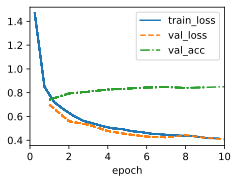

In [ ]:
# Thiết lập các siêu tham số
hparams = {'num_outputs':10, 'num_hiddens_1':256, 'num_hiddens_2':256,
           'dropout_1':0.5, 'dropout_2':0.5, 'lr':0.1}
# Khởi tạo mô hình
model = DropoutMLPScratch(**hparams)
# Tải tập dữ liệu FashionMNIST
data = d2l.FashionMNIST(batch_size=256)
# Thiết lập trình huấn luyện tối đa 10 epochs
trainer = d2l.Trainer(max_epochs=10)
# Tiến hành huấn luyện mô hình
trainer.fit(model, data)

## [**Triển khai Ngắn gọn (Concise Implementation)**]

Với các API cấp cao, tất cả những gì chúng ta cần làm là thêm một lớp `Dropout` sau mỗi lớp liên kết đầy đủ (fully connected layer),
truyền xác suất dropout làm đối số duy nhất vào hàm khởi tạo của nó.
Trong quá trình huấn luyện, lớp `Dropout` sẽ ngẫu nhiên loại bỏ các đầu ra của lớp trước đó
(hoặc tương đương là các đầu vào của lớp tiếp theo) theo xác suất dropout đã chỉ định.
Khi không ở chế độ huấn luyện, lớp `Dropout` chỉ đơn giản là truyền dữ liệu qua trực tiếp trong quá trình kiểm thử.

In [ ]:
class DropoutMLP(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens_1, num_hiddens_2,
                 dropout_1, dropout_2, lr):
        super().__init__()
        self.save_hyperparameters()
        # Định nghĩa mạng nơ-ron tuần tự bằng cách sử dụng các lớp sẵn có của PyTorch
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(num_hiddens_1), nn.ReLU(),
            nn.Dropout(dropout_1), # Áp dụng lớp Dropout tích hợp sẵn
            nn.LazyLinear(num_hiddens_2), nn.ReLU(),
            nn.Dropout(dropout_2), # Áp dụng lớp Dropout tích hợp sẵn
            nn.LazyLinear(num_outputs))

Tiếp theo, chúng ta [**huấn luyện mô hình**].

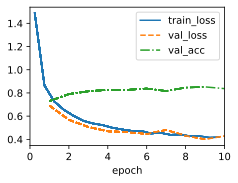

In [ ]:
# Khởi tạo mô hình gọn và tiến hành huấn luyện
model = DropoutMLP(**hparams)
trainer.fit(model, data)

## Tóm tắt

Bên cạnh việc kiểm soát số lượng chiều và kích thước của vectơ trọng số, dropout là một công cụ khác để tránh hiện tượng quá khớp (overfitting). Thông thường các công cụ này được sử dụng cùng nhau.
Lưu ý rằng dropout chỉ được sử dụng trong quá trình huấn luyện:
nó thay thế một giá trị kích hoạt $h$ bằng một biến ngẫu nhiên có giá trị kỳ vọng là $h$.


## Bài tập

1. Điều gì xảy ra nếu bạn thay đổi xác suất dropout cho lớp thứ nhất và lớp thứ hai? Cụ thể, điều gì xảy ra nếu bạn hoán đổi xác suất của cả hai lớp? Hãy thiết kế một thí nghiệm để trả lời các câu hỏi này, mô tả kết quả của bạn một cách định lượng và tóm tắt các kết luận định tính rút ra được.
2. Tăng số lượng epochs và so sánh kết quả đạt được khi sử dụng dropout với khi không sử dụng nó.
3. Phương sai của các giá trị kích hoạt trong mỗi lớp ẩn là bao nhiêu khi áp dụng và không áp dụng dropout? Hãy vẽ một biểu đồ để chỉ ra sự phát triển của đại lượng này theo thời gian cho cả hai mô hình.
4. Tại sao dropout thường không được sử dụng tại thời điểm kiểm thử (test time)?
5. Sử dụng mô hình trong phần này làm ví dụ, hãy so sánh tác động của việc sử dụng dropout và suy giảm trọng số (weight decay). Điều gì xảy ra khi dropout và weight decay được sử dụng cùng một lúc? Kết quả có tính chất cộng dồn (additive) không? Có gặp phải tình trạng hiệu suất giảm dần (diminished returns) hay tệ hơn không? Chúng có triệt tiêu lẫn nhau không?
6. Điều gì xảy ra nếu chúng ta áp dụng dropout vào từng trọng số cá nhân của ma trận trọng số thay vì các giá trị kích hoạt (activations)?
7. Hãy sáng tạo một kỹ thuật khác để truyền nhiễu ngẫu nhiên ở mỗi lớp khác với kỹ thuật dropout tiêu chuẩn. Bạn có thể phát triển một phương pháp vượt trội hơn dropout trên tập dữ liệu Fashion-MNIST (cho một kiến trúc cố định) không?

[Thảo luận](https://discuss.d2l.ai/t/101)